# Joint BRDF + Drift Estimation: Synthetic Demonstration

Model system (per wavelength; single site shown here):

$$R_{t} = a + b\,t \qquad \text{(1) radiometric response}$$

$$\rho_{\theta,t} = \left[c + d\cos\theta\right]\left[a + b\,t\right] \qquad \text{(2) observation model}$$

$$\rho_{\theta,t} = \left[\alpha + \beta\cos\theta\right]\left[1 + \gamma\,t\right] \qquad \text{(3) fitted form}$$

Parameter mapping: $\alpha = ca$, $\beta = da$, $\gamma = b/a$. Equation 3 is Eq. 2 with the response's absolute level $a$ absorbed into the geometry bracket, pinning the time bracket to 1 at $t=0$. $\gamma$ is then the fractional drift rate (fraction/yr), and $\beta/\alpha = d/c$ is the site's fractional directional sensitivity.

Eq. 3 is bilinear (products of unknowns: $\alpha\gamma$, $\beta\gamma$), so it is fit by alternating least squares (ALS) rather than one linear solve. Uncertainty via scene-level bootstrap.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

rng = np.random.default_rng(42)
plt.rcParams['figure.dpi'] = 1000

## 1. Synthetic scenes

150 acquisitions over 3.5 yr. SZA drawn independently of time (non-sun-synchronous sampling). Truth: drift $b/a = -0.385$ %/yr, directional sensitivity $d/c = 0.212$. Noise: 0.3 % multiplicative.

In [9]:
A, B = 0.520, -0.002          # Eq. 1
C, D = 0.85, 0.18             # directional bracket
GAMMA_TRUE = B / A            # -0.385 %/yr

N   = 150
t   = np.sort(rng.uniform(0.0, 3.5, N))
sza = rng.uniform(15.0, 55.0, N)
g   = np.cos(np.radians(sza))

rho = (C + D*g) * (A + B*t) * (1 + 0.003*rng.standard_normal(N))

print(f"corr(t, SZA) = {np.corrcoef(t, sza)[0,1]:+.3f}   (separability check)")

corr(t, SZA) = -0.073   (separability check)




In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

sc = axes[0].scatter(t, rho, c=sza, cmap='viridis', s=14)
axes[0].set_xlabel('t (yr)'); axes[0].set_ylabel(r'$\rho$')
axes[0].set_title('vs time — drift hidden under geometry scatter')
plt.colorbar(sc, ax=axes[0], label='SZA (deg)')

sc2 = axes[1].scatter(g, rho, c=t, cmap='plasma', s=14)
axes[1].set_xlabel(r'$\cos\theta$'); axes[1].set_ylabel(r'$\rho$')
axes[1].set_title('vs geometry — directional signal dominant')
plt.colorbar(sc2, ax=axes[1], label='t (yr)')

plt.tight_layout(); plt.show()

## 2. Fit Eq. 3 by alternating least squares

Two half-steps, each an exact linear solve, looped to convergence:

- freeze $\gamma$: $\;u = \rho/(1+\gamma t)$ obeys $u = \alpha + \beta g$ → 2-column OLS
- freeze $(\alpha,\beta)$: $\;v = \rho/(\alpha+\beta g) - 1$ obeys $v = \gamma t$ → 1-column OLS

In [4]:
def fit_als(t, g, rho, tol=1e-13, max_iter=500):
    gamma, trace = 0.0, [0.0]
    Xg = np.column_stack([np.ones_like(g), g])
    for it in range(max_iter):
        (alpha, beta), *_ = np.linalg.lstsq(Xg, rho/(1 + gamma*t), rcond=None)
        v = rho/(alpha + beta*g) - 1
        gamma_new = (t @ v) / (t @ t)
        trace.append(gamma_new)
        if abs(gamma_new - gamma) < tol:
            return alpha, beta, gamma_new, np.array(trace)
        gamma = gamma_new
    return alpha, beta, gamma, np.array(trace)

alpha, beta, gamma, trace = fit_als(t, g, rho)

print(f"{'':>18}{'fitted':>10}{'true':>10}")
print(f"{'alpha (=ca)':>18}{alpha:>10.5f}{C*A:>10.5f}")
print(f"{'beta  (=da)':>18}{beta:>10.5f}{D*A:>10.5f}")
print(f"{'gamma (=b/a)':>18}{gamma:>10.6f}{GAMMA_TRUE:>10.6f}")
print(f"\ndrift          gamma      = {100*gamma:+.3f} %/yr  (true {100*GAMMA_TRUE:+.3f})")
print(f"dir. sens.     beta/alpha = {beta/alpha:.4f}  (true {D/C:.4f})")

# independent check with a general optimizer
sol = least_squares(lambda p: (p[0]+p[1]*g)*(1+p[2]*t) - rho, x0=[rho.mean(), 0, 0])
print(f"\nscipy least_squares agreement: max|diff| = "
      f"{np.max(np.abs(sol.x - [alpha, beta, gamma])):.1e}")

                      fitted      true
       alpha (=ca)   0.44186   0.44200
       beta  (=da)   0.09418   0.09360
      gamma (=b/a) -0.004228 -0.003846

drift          gamma      = -0.423 %/yr  (true -0.385)
dir. sens.     beta/alpha = 0.2131  (true 0.2118)

scipy least_squares agreement: max|diff| = 4.1e-06


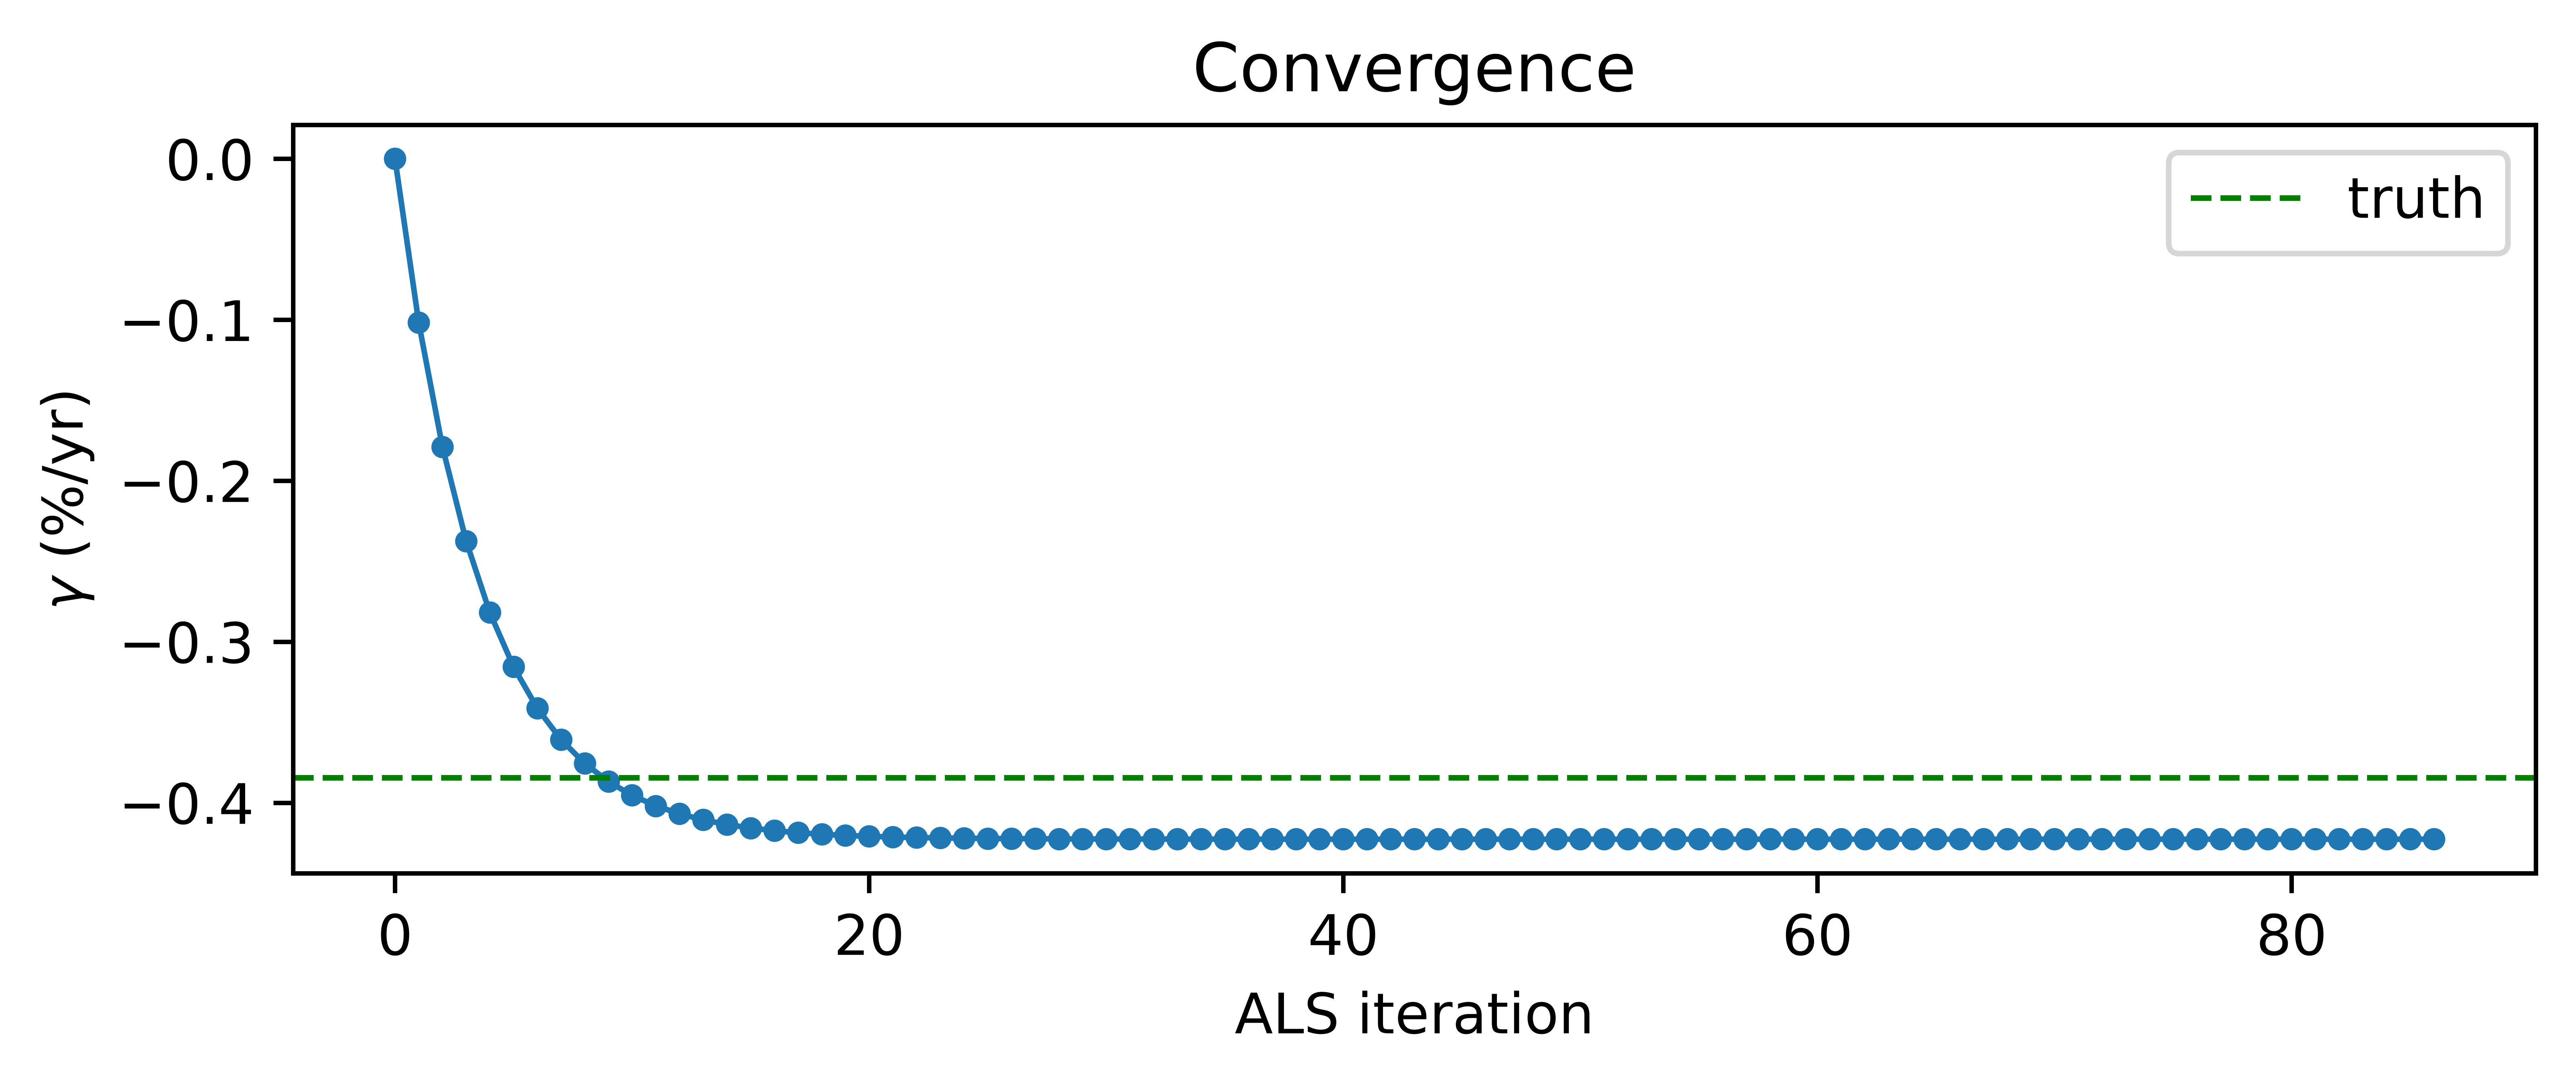

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(100*trace, 'o-', ms=3, lw=1)
ax.axhline(100*GAMMA_TRUE, color='g', ls='--', lw=1, label='truth')
ax.set_xlabel('ALS iteration'); ax.set_ylabel(r'$\gamma$ (%/yr)')
ax.set_title('Convergence')
ax.legend()
plt.tight_layout(); plt.show()

## 3. The decomposition

Eq. 3 factorizes each observation into (site factor) × (drift curve). Dividing observations by the fitted site factor removes the geometry scatter and exposes the normalized response $1 + \gamma t$.



In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

sc = axes[0].scatter(t, rho, c=sza, cmap='viridis', s=14)
axes[0].set_xlabel('t (yr)'); axes[0].set_ylabel(r'$\rho$')
axes[0].set_title('Raw')
plt.colorbar(sc, ax=axes[0], label='SZA (deg)')

norm = rho / (alpha + beta*g)
sc2 = axes[1].scatter(t, norm, c=sza, cmap='viridis', s=14)
tt = np.linspace(0, 3.5, 50)
axes[1].plot(tt, 1 + gamma*tt, 'r-', lw=1.5, label=r'$1+\gamma t$')
axes[1].axhline(1, color='k', lw=0.6, ls=':')
axes[1].set_xlabel('t (yr)'); axes[1].set_ylabel(r'$\rho\,/\,(\alpha+\beta g)$')
axes[1].set_title('Site factor divided out')
axes[1].legend()
plt.colorbar(sc2, ax=axes[1], label='SZA (deg)')

plt.tight_layout(); plt.show()

Right panel: color no longer organizes the points (geometry captured by the site factor); the remaining structure is the drift line.

## 4. Residual diagnostics

Structureless residuals against both regressors → model form adequate; scatter matches the injected 0.3 % noise.

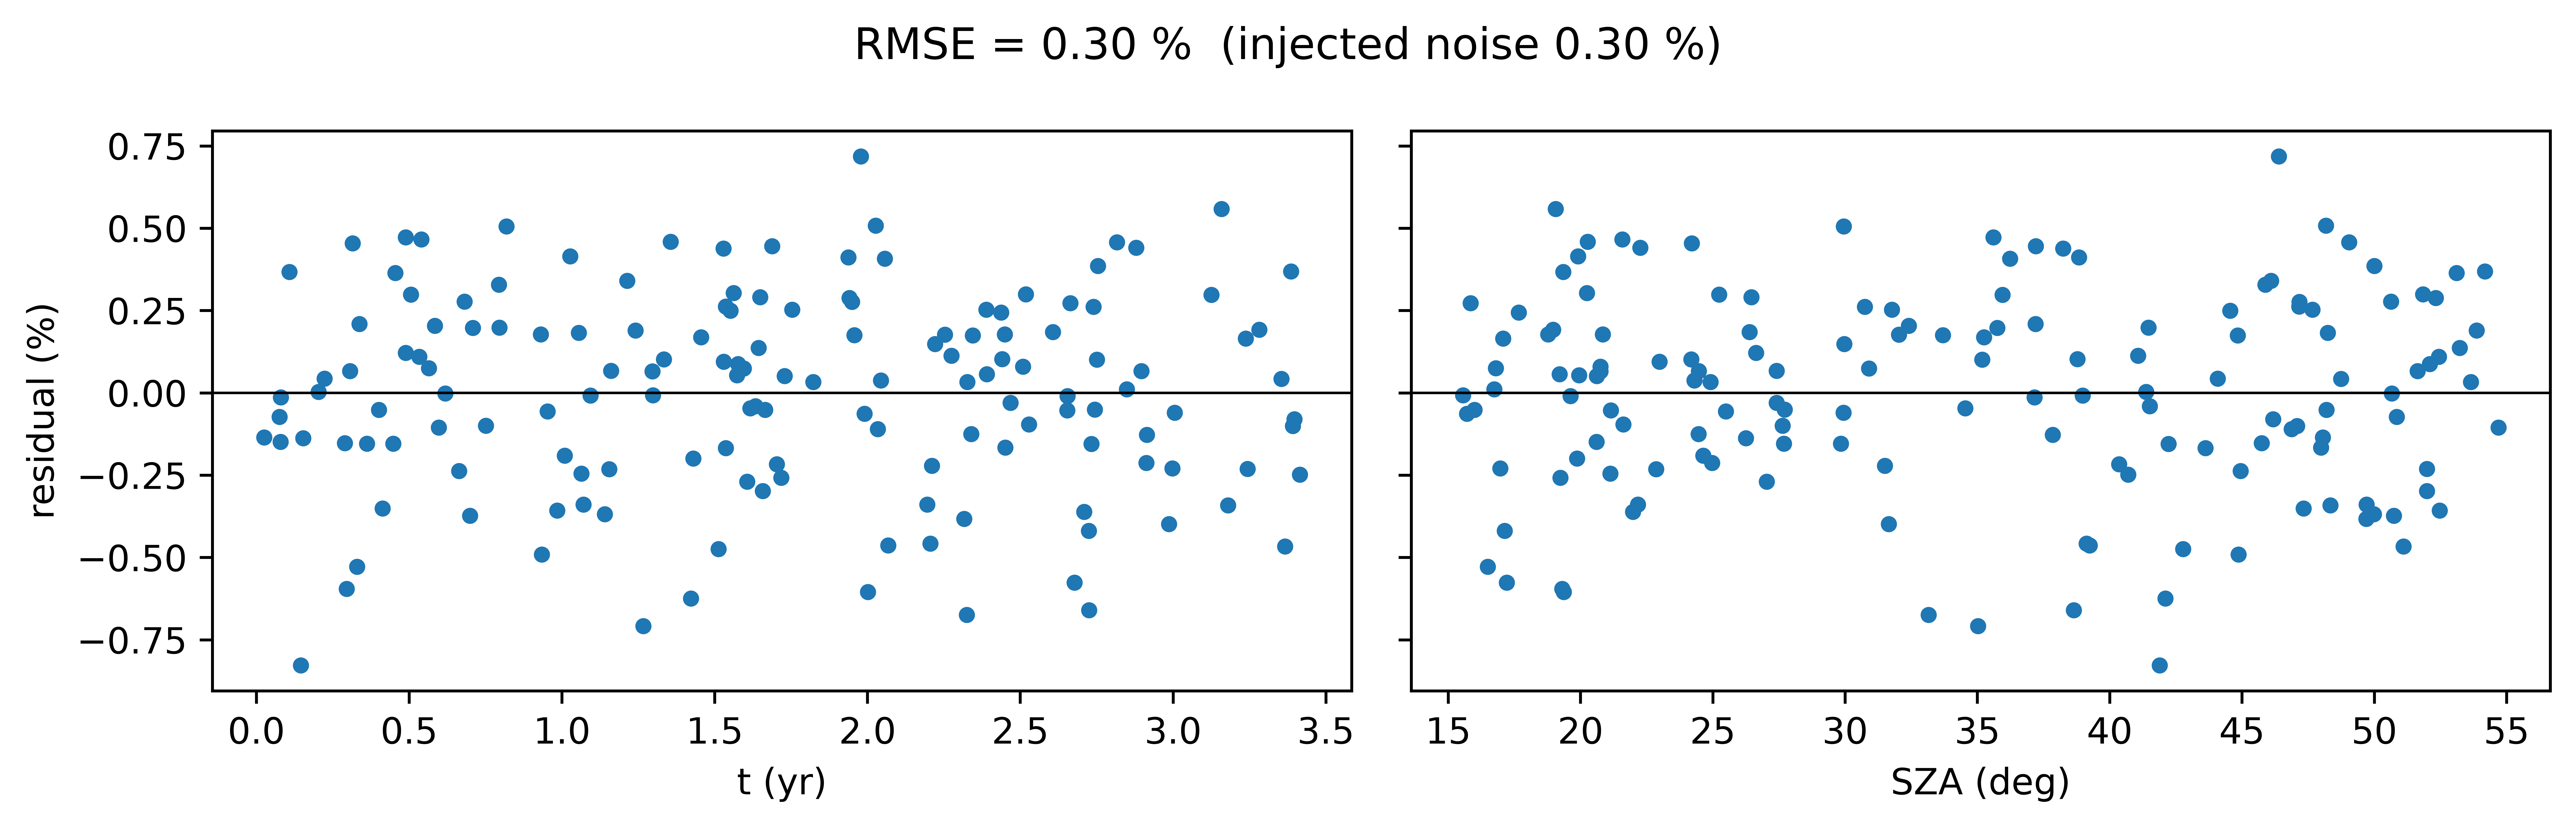

In [7]:
resid = rho - (alpha + beta*g)*(1 + gamma*t)
rel = 100 * resid / rho

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, x, lab in [(axes[0], t, 't (yr)'), (axes[1], sza, 'SZA (deg)')]:
    ax.scatter(x, rel, s=12)
    ax.axhline(0, color='k', lw=0.7)
    ax.set_xlabel(lab)
axes[0].set_ylabel('residual (%)')
fig.suptitle(f'RMSE = {rel.std():.2f} %  (injected noise 0.30 %)')
plt.tight_layout(); plt.show()

## 5. Uncertainty: scene-level bootstrap

Resample the 150 scenes with replacement, refit, 1000 times. The spread of refitted $\gamma$ values is the drift uncertainty. (On real data this replaces the analytical SE because scenes sharing atmospheric conditions violate its independence assumption; here it also serves as the generic wrapper that works unchanged around the iterative fit.)

In [8]:
BOOT = 1000
gammas = []
for _ in range(BOOT):
    idx = rng.integers(0, N, N)
    ti, gi, ri = t[idx], g[idx], rho[idx]
    if np.ptp(ti) < 0.5 or np.ptp(gi) < 0.05:      # degenerate resample guard
        continue
    gammas.append(fit_als(ti, gi, ri)[2])
gammas = 100 * np.array(gammas)

se = gammas.std()
ci = np.percentile(gammas, [2.5, 97.5])
print(f"resamples kept : {len(gammas)}/{BOOT}")
print(f"drift          : {100*gamma:+.3f} %/yr")
print(f"bootstrap SE   : {se:.3f} %/yr")
print(f"95% CI         : [{ci[0]:+.3f}, {ci[1]:+.3f}] %/yr")
print(f"truth          : {100*GAMMA_TRUE:+.3f} %/yr  ({'inside' if ci[0] <= 100*GAMMA_TRUE <= ci[1] else 'OUTSIDE'} CI)")

resamples kept : 1000/1000
drift          : -0.423 %/yr
bootstrap SE   : 0.025 %/yr
95% CI         : [-0.470, -0.374] %/yr
truth          : -0.385 %/yr  (inside CI)


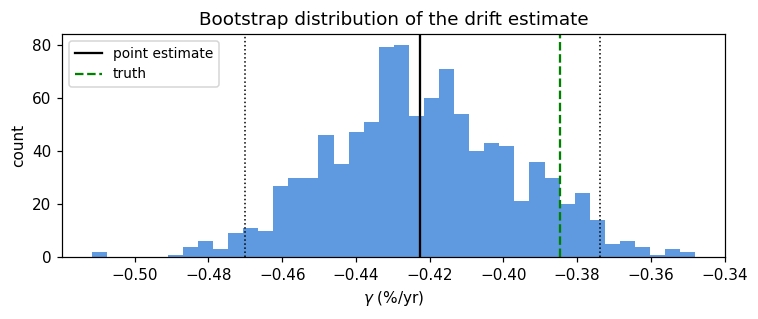

In [9]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(gammas, bins=40, color='#2a78d6', alpha=0.75)
ax.axvline(100*gamma, color='k', lw=1.5, label='point estimate')
ax.axvline(100*GAMMA_TRUE, color='g', ls='--', lw=1.5, label='truth')
for c in ci:
    ax.axvline(c, color='k', ls=':', lw=1)
ax.set_xlabel(r'$\gamma$ (%/yr)'); ax.set_ylabel('count')
ax.set_title('Bootstrap distribution of the drift estimate')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## Result

Point estimate and 95% scene-bootstrap CI printed above; on this realization, $\hat\gamma = -0.42 \pm 0.03$ %/yr against a truth of $-0.385$ %/yr.

Production differences from this demo: multiple sites share one $\gamma_\lambda$ (each site keeps its own $\alpha_{x,\lambda},\beta_{x,\lambda}$; the $\gamma$ half-step pools all sites' scenes), one fit per channel per product level (L1B radiance and L2A reflectance in parallel), scene rows are patch-aggregated with QC masking upstream, and the bootstrap is stratified in time.